# Trial 3 — Improved Loss Function

**What changed from Trial 2:**
- Combined loss: `α·MSE + β·(1 − Pearson_r) + γ·Directional` replaces plain weighted MSE
- Uniform `ReduceLROnPlateau` across all models (no DirectionalLRScheduler)
- Simple ensemble of 3 models as final output
- Daily snapshots only (adaptive subdaily removed for cleaner comparison)

**No files need to be deleted** — all outputs use a `trial3_` prefix.

In [1]:
# Cell 1 – Imports & Configuration
import os, time, copy, pickle, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr
from tqdm import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

warnings.filterwarnings('ignore')
pd.set_option('display.float_format', lambda x: f'{x:.4f}')

# ── Paths ────────────────────────────────────────────────────────────────────────────
_cwd        = os.getcwd()
PROJECT_DIR = os.path.abspath(os.path.join(_cwd, '..')) \
              if os.path.basename(_cwd) == 'notebooks' else _cwd
DATA_DIR    = os.path.join(PROJECT_DIR, 'data', 'processed')
MODELS_DIR  = os.path.join(PROJECT_DIR, 'models')
PREDS_DIR   = os.path.join(PROJECT_DIR, 'outputs', 'predictions')
PLOTS_DIR   = os.path.join(PROJECT_DIR, 'outputs', 'plots')

# ── Hyperparameters ─────────────────────────────────────────────────────────────────
N_STOCKS    = 95
LOOKBACK    = 20
HORIZON     = 5
TRAIN_RATIO = 0.70

BATCH_SIZE    = 16
BATCH_SIZE_3D = 8
LR            = 1e-3
MAX_EPOCHS    = 50
PATIENCE      = 8
WEIGHT_DECAY  = 1e-4

# Combined loss weights
ALPHA = 0.5   # MSE
BETA  = 0.3   # 1 - Pearson
GAMMA = 0.2   # Directional

# ── Device ──────────────────────────────────────────────────────────────────────────────
device  = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
PIN_MEM = device.type == 'cuda'

print(f'Device      : {device}')
print(f'Project dir : {PROJECT_DIR}')
print(f'PyTorch     : {torch.__version__}')
print(f'Loss weights: alpha={ALPHA} (MSE)  beta={BETA} (Pearson)  gamma={GAMMA} (Directional)')

Device      : cuda
Project dir : c:\Users\HP\Documents\InterStockRelation_Paper\InterStockRelation
PyTorch     : 2.6.0+cu124
Loss weights: alpha=0.5 (MSE)  beta=0.3 (Pearson)  gamma=0.2 (Directional)


In [2]:
# Cell 2 – Load Processed Data
# All heavy R(t) computation, pair caching, and Fiedler reordering
# was done in trial2 and persisted to data/processed/.
# This cell loads the pre-built correlation video directly.

corr_video  = np.load(os.path.join(DATA_DIR, 'corr_video.npy'))
fiedler_ord = np.load(os.path.join(DATA_DIR, 'fiedler_order.npy'))
snap_ts     = np.load(os.path.join(DATA_DIR, 'snap_timesteps.npy'), allow_pickle=True)

with open(os.path.join(DATA_DIR, 'pair_meta.pkl'), 'rb') as f:
    pair_meta = pickle.load(f)

with open(os.path.join(DATA_DIR, 'video_meta.pkl'), 'rb') as f:
    video_meta = pickle.load(f)

tickers = pair_meta['tickers']
N_SNAPS = corr_video.shape[0]

print(f'corr_video  : {corr_video.shape}  dtype={corr_video.dtype}')
print(f'N stocks    : {len(tickers)}')
print(f'N snapshots : {N_SNAPS}')
print(f'Snap range  : {snap_ts[0]} -> {snap_ts[-1]}')
print(f'Sample tickers: {tickers[:8]}')

corr_video  : (1157, 95, 95)  dtype=float32
N stocks    : 95
N snapshots : 1157
Snap range  : 375 -> 87075
Sample tickers: ['ABB', 'ADANIENSOL', 'ADANIENT', 'ADANIGREEN', 'ADANIPORTS', 'ADANIPOWER', 'AMBUJACEM', 'APOLLOHOSP']


In [3]:
# Cell 3 – Frame MSE, Stratified Split, Dataset & DataLoaders

# ── Per-snapshot volatility (MSE to the frame HORIZON steps ahead) ─────────
n_valid   = N_SNAPS - HORIZON
frame_mse = np.array([
    float(np.mean((corr_video[t] - corr_video[t + HORIZON]) ** 2))
    for t in range(n_valid)
], dtype=np.float32)

volatility_threshold = float(np.median(frame_mse))
print(f'Volatility threshold (median frame MSE): {volatility_threshold:.6f}')

# ── Stratified train / val split (volatile + stable balanced) ────────────
valid_snaps = np.array([s for s in range(n_valid) if s >= LOOKBACK])
snap_v      = frame_mse[valid_snaps]

volatile_snaps = valid_snaps[snap_v >= volatility_threshold]
stable_snaps   = valid_snaps[snap_v <  volatility_threshold]

np.random.seed(42)
vol_train = np.random.choice(volatile_snaps, int(len(volatile_snaps) * TRAIN_RATIO), replace=False)
vol_val   = np.setdiff1d(volatile_snaps, vol_train)
sta_train = np.random.choice(stable_snaps,  int(len(stable_snaps)  * TRAIN_RATIO), replace=False)
sta_val   = np.setdiff1d(stable_snaps,  sta_train)

train_snaps = np.sort(np.concatenate([vol_train, sta_train]))
val_snaps   = np.sort(np.concatenate([vol_val,   sta_val]))

print(f'Train: {len(train_snaps)} ({len(vol_train)} volatile, {len(sta_train)} stable)')
print(f'Val  : {len(val_snaps)}   ({len(vol_val)} volatile, {len(sta_val)} stable)')

# ── Baselines ───────────────────────────────────────────────────────────────────
persistence_mse  = float(np.mean([
    np.mean((corr_video[s] - corr_video[s + HORIZON]) ** 2) for s in val_snaps
]))
mean_train_frame = corr_video[train_snaps].mean(axis=0)
mean_frame_mse   = float(np.mean([
    np.mean((mean_train_frame - corr_video[s + HORIZON]) ** 2) for s in val_snaps
]))
val_currents = corr_video[val_snaps - 1].astype(np.float32)  # frame just before target window

print(f'\nPersistence MSE : {persistence_mse:.6f}')
print(f'Mean-frame MSE  : {mean_frame_mse:.6f}')

# ── Dataset ───────────────────────────────────────────────────────────────────────────
class CorrVideoDataset(Dataset):
    def __init__(self, snap_indices):
        self.snaps = snap_indices

    def __len__(self):
        return len(self.snaps)

    def __getitem__(self, idx):
        s      = self.snaps[idx]
        frames = corr_video[s - LOOKBACK : s].astype(np.float32)  # (L, 95, 95)
        future = corr_video[s + HORIZON].astype(np.float32)        # (95, 95)
        weight = float(frame_mse[s])
        return (
            torch.from_numpy(frames),
            torch.from_numpy(future),
            torch.tensor(weight, dtype=torch.float32),
        )

train_ds = CorrVideoDataset(train_snaps)
val_ds   = CorrVideoDataset(val_snaps)

train_dl = DataLoader(train_ds, batch_size=BATCH_SIZE,    shuffle=True,  num_workers=0, pin_memory=PIN_MEM)
val_dl   = DataLoader(val_ds,   batch_size=BATCH_SIZE,    shuffle=False, num_workers=0, pin_memory=PIN_MEM)
train_dl_3d = DataLoader(train_ds, batch_size=BATCH_SIZE_3D, shuffle=True,  num_workers=0, pin_memory=PIN_MEM)
val_dl_3d   = DataLoader(val_ds,   batch_size=BATCH_SIZE_3D, shuffle=False, num_workers=0, pin_memory=PIN_MEM)

print(f'\nDataset ready  train={len(train_ds)}  val={len(val_ds)}')

Volatility threshold (median frame MSE): 0.121262
Train: 792 (389 volatile, 403 stable)
Val  : 340   (167 volatile, 173 stable)

Persistence MSE : 0.128137
Mean-frame MSE  : 0.071299

Dataset ready  train=792  val=340


In [4]:
# Cell 4 – Combined Loss Function
#
# Trial 2 used weighted MSE only.  The MSE-optimal prediction is the conditional
# mean of the target, which explains why all trial-2 models barely beat the
# mean-frame baseline.  Three complementary terms fix this:
#
#   MSE term       — keeps predictions in the right value range
#   Pearson term   — rewards structural (shape) similarity of the matrix
#   Directional    — penalises wrong-sign correlation changes (the trading signal)
#
# loss = alpha * MSE  +  beta * (1 - Pearson_r)  +  gamma * Directional

def combined_loss(pred, target, current, weights,
                  alpha=ALPHA, beta=BETA, gamma=GAMMA):
    """
    pred, target, current : (B, N, N)
    weights               : (B,)  per-sample volatility weights
    """
    # 1. Volatility-weighted MSE
    per_sample = ((pred - target) ** 2).mean(dim=(1, 2))   # (B,)
    w          = weights / weights.sum() * len(weights)
    mse_loss   = (w * per_sample).mean()

    # 2. Pearson correlation loss — maximise structural similarity
    pred_flat = pred.flatten(1)                             # (B, N^2)
    tgt_flat  = target.flatten(1)
    pred_c    = pred_flat - pred_flat.mean(dim=1, keepdim=True)
    tgt_c     = tgt_flat  - tgt_flat.mean(dim=1, keepdim=True)
    pearson   = (pred_c * tgt_c).sum(dim=1) / (
                 pred_c.norm(dim=1) * tgt_c.norm(dim=1) + 1e-8)
    pearson_loss = (1.0 - pearson).mean()

    # 3. Soft directional loss — zero when direction correct, positive when wrong
    # relu(-(pred_delta * true_delta)) is 0 when signs agree, |product| when they don't
    pred_delta = pred    - current
    true_delta = target  - current
    dir_loss   = F.relu(-(pred_delta * true_delta)).mean()

    return alpha * mse_loss + beta * pearson_loss + gamma * dir_loss


# Quick sanity check on random tensors
with torch.no_grad():
    _p  = torch.randn(4, N_STOCKS, N_STOCKS)
    _t  = torch.randn(4, N_STOCKS, N_STOCKS)
    _c  = torch.randn(4, N_STOCKS, N_STOCKS)
    _w  = torch.ones(4)
    _l  = combined_loss(_p, _t, _c, _w)
print(f'Combined loss sanity check (random tensors): {_l.item():.4f}  (should be > 0)')

Combined loss sanity check (random tensors): 1.3507  (should be > 0)


In [5]:
# Cell 5 – Model Architectures
# Three spatiotemporal architectures, identical to trial2 weights/structure.
# The only change is in what they optimise (the loss), not how they are built.

# ── Model 1: CNN + LSTM ───────────────────────────────────────────────────────
class FrameCNN(nn.Module):
    def __init__(self, out_dim=256):
        super().__init__()
        self.conv1 = nn.Conv2d(1,  16, 5, padding=2)
        self.conv2 = nn.Conv2d(16, 32, 5, padding=2)
        self.conv3 = nn.Conv2d(32, 64, 3, padding=1)
        self.bn1   = nn.BatchNorm2d(16)
        self.bn2   = nn.BatchNorm2d(32)
        self.bn3   = nn.BatchNorm2d(64)
        self.pool  = nn.MaxPool2d(2, 2)
        self.drop  = nn.Dropout2d(0.2)
        self.apool = nn.AdaptiveAvgPool2d((6, 6))
        self.fc    = nn.Linear(64 * 6 * 6, out_dim)
        self.norm  = nn.LayerNorm(out_dim)

    def forward(self, x):
        x = self.pool(F.relu(self.bn1(self.conv1(x))))
        x = self.drop(self.pool(F.relu(self.bn2(self.conv2(x)))))
        x = F.relu(self.bn3(self.conv3(x)))
        x = self.apool(x).flatten(1)
        return self.norm(F.relu(self.fc(x)))


class CorrVideoReg(nn.Module):
    def __init__(self, cnn_dim=256, lstm_hidden=256, lstm_layers=2,
                 n_stocks=N_STOCKS, dropout=0.3):
        super().__init__()
        self.n = n_stocks
        self.cnn     = FrameCNN(cnn_dim)
        self.lstm    = nn.LSTM(cnn_dim, lstm_hidden, lstm_layers,
                               batch_first=True,
                               dropout=dropout if lstm_layers > 1 else 0.0)
        self.norm    = nn.LayerNorm(lstm_hidden)
        self.dropout = nn.Dropout(dropout)
        self.decoder = nn.Sequential(
            nn.Linear(lstm_hidden, 512),  nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(512, 1024),         nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(1024, n_stocks * n_stocks), nn.Tanh()
        )

    def forward(self, frames):
        B, L, H, W = frames.shape
        cnn_out    = self.cnn(frames.reshape(B * L, 1, H, W))
        cnn_seq    = cnn_out.reshape(B, L, -1)
        out, _     = self.lstm(cnn_seq)
        h          = self.dropout(self.norm(out[:, -1, :]))
        return self.decoder(h).reshape(B, self.n, self.n)


# ── Model 2: Pure 3D CNN ──────────────────────────────────────────────────────
class Corr3DCNN(nn.Module):
    def __init__(self, n_stocks=N_STOCKS, dropout=0.3):
        super().__init__()
        self.n = n_stocks
        self.conv1 = nn.Conv3d(1,   16,  (3, 3, 3), padding=(1, 1, 1))
        self.conv2 = nn.Conv3d(16,  32,  (3, 5, 5), padding=(1, 2, 2))
        self.conv3 = nn.Conv3d(32,  64,  (5, 3, 3), padding=(2, 1, 1))
        self.conv4 = nn.Conv3d(64,  128, (3, 3, 3), padding=(1, 1, 1))
        self.bn1   = nn.BatchNorm3d(16)
        self.bn2   = nn.BatchNorm3d(32)
        self.bn3   = nn.BatchNorm3d(64)
        self.bn4   = nn.BatchNorm3d(128)
        self.tpool = nn.AdaptiveAvgPool3d((1, 6, 6))
        self.drop  = nn.Dropout(dropout)
        self.fc    = nn.Linear(128 * 6 * 6, 512)
        self.fnorm = nn.LayerNorm(512)
        self.decoder = nn.Sequential(
            nn.Linear(512, 512),  nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(512, 1024), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(1024, n_stocks * n_stocks), nn.Tanh()
        )

    def forward(self, frames):
        B = frames.size(0)
        x = frames.unsqueeze(1)
        x = F.relu(self.bn1(self.conv1(x)))
        x = F.relu(self.bn2(self.conv2(x)))
        x = F.relu(self.bn3(self.conv3(x)))
        x = F.relu(self.bn4(self.conv4(x)))
        x = self.drop(self.tpool(x).flatten(1))
        x = self.drop(self.fnorm(F.relu(self.fc(x))))
        return self.decoder(x).reshape(B, self.n, self.n)


# ── Model 3: ConvLSTM ─────────────────────────────────────────────────────────
class ConvLSTMCell(nn.Module):
    def __init__(self, in_ch, hid_ch, k=3):
        super().__init__()
        self.hid_ch = hid_ch
        self.conv   = nn.Conv2d(in_ch + hid_ch, 4 * hid_ch, k, padding=k // 2)

    def forward(self, x, h, c):
        i, f, g, o = self.conv(torch.cat([x, h], dim=1)).chunk(4, dim=1)
        c_next = torch.sigmoid(f) * c + torch.sigmoid(i) * torch.tanh(g)
        h_next = torch.sigmoid(o) * torch.tanh(c_next)
        return h_next, c_next

    def init_hidden(self, B, sp, device):
        z = torch.zeros(B, self.hid_ch, sp, sp, device=device)
        return z, z.clone()


class ConvLSTMReg(nn.Module):
    def __init__(self, n_stocks=N_STOCKS, sp=24, hid_ch=32, dropout=0.3):
        super().__init__()
        self.n  = n_stocks
        self.sp = sp
        self.hid_ch = hid_ch
        self.down = nn.Sequential(
            nn.Conv2d(1,  16, 3, padding=1), nn.BatchNorm2d(16), nn.ReLU(),
            nn.Conv2d(16, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(),
            nn.AdaptiveAvgPool2d((sp, sp)),
            nn.Conv2d(32, hid_ch, 1),
        )
        self.cell1  = ConvLSTMCell(hid_ch, hid_ch)
        self.cell2  = ConvLSTMCell(hid_ch, hid_ch)
        self.lnorm  = nn.LayerNorm([hid_ch, sp, sp])
        self.drop2d = nn.Dropout2d(dropout)
        flat = hid_ch * sp * sp
        self.decoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(flat, 1024), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(1024, 2048), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(2048, n_stocks * n_stocks), nn.Tanh()
        )

    def forward(self, frames):
        B, L, H, W = frames.shape
        enc = self.down(frames.reshape(B * L, 1, H, W))
        enc = enc.reshape(B, L, self.hid_ch, self.sp, self.sp)
        h1, c1 = self.cell1.init_hidden(B, self.sp, frames.device)
        h2, c2 = self.cell2.init_hidden(B, self.sp, frames.device)
        for t in range(L):
            h1, c1 = self.cell1(enc[:, t], h1, c1)
            h1     = self.drop2d(h1)
            h2, c2 = self.cell2(h1, h2, c2)
        h2 = self.lnorm(h2)
        return self.decoder(h2).reshape(B, self.n, self.n)


# ── Parameter counts ─────────────────────────────────────────────────────────
def n_params(m):
    return sum(p.numel() for p in m.parameters() if p.requires_grad)

_m1 = CorrVideoReg().to(device)
_m2 = Corr3DCNN().to(device)
_m3 = ConvLSTMReg().to(device)
print(f'CNN+LSTM   params: {n_params(_m1):>10,}')
print(f'3D CNN     params: {n_params(_m2):>10,}')
print(f'ConvLSTM   params: {n_params(_m3):>10,}')
del _m1, _m2, _m3

CNN+LSTM   params: 11,583,265
3D CNN     params: 12,752,321
ConvLSTM   params: 39,657,345


In [6]:
# Cell 6 – Training Utilities

def run_epoch(model, loader, optimizer, is_train):
    model.train() if is_train else model.eval()
    total_loss = total_n = 0
    all_preds, all_futs = [], []

    ctx = torch.enable_grad() if is_train else torch.no_grad()
    with ctx:
        for frames, future, w in loader:
            frames  = frames.to(device)
            future  = future.to(device)
            w       = w.to(device)
            current = frames[:, -1, :, :]   # most recent frame before prediction

            pred = model(frames)
            loss = combined_loss(pred, future, current, w)

            if is_train:
                optimizer.zero_grad()
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                optimizer.step()

            total_loss += loss.item() * frames.size(0)
            total_n    += frames.size(0)
            all_preds.append(pred.detach().cpu().numpy())
            all_futs.append(future.cpu().numpy())

    return total_loss / total_n, np.concatenate(all_preds), np.concatenate(all_futs)


def compute_metrics(preds, futures, currents=None):
    mse = float(np.mean((preds - futures) ** 2))
    pf  = preds.reshape(-1)
    ff  = futures.reshape(-1)
    r, _ = pearsonr(pf[:500_000], ff[:500_000])
    vs_persist = (persistence_mse - mse) / persistence_mse * 100
    vs_mean    = (mean_frame_mse  - mse) / mean_frame_mse  * 100
    if currents is not None:
        pd_ = preds   - currents
        td_ = futures - currents
        dir_acc = float(np.mean(np.sign(pd_) == np.sign(td_)))
    else:
        dir_acc = None
    return dict(mse=mse, pearson_r=r, dir_acc=dir_acc,
                vs_persist=vs_persist, vs_mean=vs_mean)


def train_model(model, name, save_path, t_dl, v_dl):
    optimizer = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
                    optimizer, patience=4, factor=0.5, verbose=False)

    best_val_mse = float('inf')
    patience_ctr = 0
    history      = []
    best_preds   = None

    print(f'\n{"="*65}')
    print(f'Training: {name}')
    print(f'{"="*65}')

    for epoch in range(1, MAX_EPOCHS + 1):
        t0 = time.time()
        tr_loss, _,        _        = run_epoch(model, t_dl, optimizer, True)
        va_loss, va_preds, va_futs  = run_epoch(model, v_dl, optimizer, False)

        m        = compute_metrics(va_preds, va_futs, val_currents)
        lr_now   = optimizer.param_groups[0]['lr']
        improved = ' *' if m['mse'] < best_val_mse else ''

        scheduler.step(m['mse'])
        history.append(dict(epoch=epoch, tr_loss=tr_loss, va_mse=m['mse'],
                            pearson_r=m['pearson_r'], dir_acc=m['dir_acc'], lr=lr_now))

        print(f"Ep {epoch:>2}/{MAX_EPOCHS} | "
              f"tr={tr_loss:.5f} | va={m['mse']:.5f} | "
              f"r={m['pearson_r']:.4f} | dir={m['dir_acc']:.3f} | "
              f"vs_pers={m['vs_persist']:+.1f}% | vs_mean={m['vs_mean']:+.1f}% | "
              f"lr={lr_now:.1e} | {time.time()-t0:.0f}s{improved}")

        if m['mse'] < best_val_mse:
            best_val_mse = m['mse']
            patience_ctr = 0
            best_preds   = va_preds.copy()
            torch.save(model.state_dict(), save_path)
        else:
            patience_ctr += 1
            if patience_ctr >= PATIENCE:
                print(f'\nEarly stopping at epoch {epoch}  best_val_mse={best_val_mse:.6f}')
                break

    print(f'\nBest val MSE: {best_val_mse:.6f}')
    model.load_state_dict(torch.load(save_path, map_location=device, weights_only=True))
    return history, best_preds


print('Training utilities ready.')

Training utilities ready.


In [7]:
# Cell 7 – Train CNN + LSTM

model_cnn_lstm = CorrVideoReg(n_stocks=N_STOCKS).to(device)
save_cnn_lstm  = os.path.join(MODELS_DIR, 'trial3_cnn_lstm_best.pt')

hist_cnn_lstm, preds_cnn_lstm = train_model(
    model_cnn_lstm, 'CNN+LSTM', save_cnn_lstm, train_dl, val_dl
)

np.save(os.path.join(PREDS_DIR, 'trial3_cnn_lstm_val_preds.npy'), preds_cnn_lstm)
with open(os.path.join(MODELS_DIR, 'trial3_cnn_lstm_history.pkl'), 'wb') as f:
    pickle.dump(hist_cnn_lstm, f)
print('CNN+LSTM done.')


Training: CNN+LSTM
Ep  1/50 | tr=0.25010 | va=0.07932 | r=0.2943 | dir=0.707 | vs_pers=+38.1% | vs_mean=-11.3% | lr=1.0e-03 | 5s *
Ep  2/50 | tr=0.22482 | va=0.07817 | r=0.2983 | dir=0.708 | vs_pers=+39.0% | vs_mean=-9.6% | lr=1.0e-03 | 4s *
Ep  3/50 | tr=0.22286 | va=0.07814 | r=0.3001 | dir=0.708 | vs_pers=+39.0% | vs_mean=-9.6% | lr=1.0e-03 | 4s *
Ep  4/50 | tr=0.22218 | va=0.07460 | r=0.2574 | dir=0.719 | vs_pers=+41.8% | vs_mean=-4.6% | lr=1.0e-03 | 4s *
Ep  5/50 | tr=0.22219 | va=0.07426 | r=0.3041 | dir=0.717 | vs_pers=+42.0% | vs_mean=-4.2% | lr=1.0e-03 | 4s *
Ep  6/50 | tr=0.21989 | va=0.07590 | r=0.3121 | dir=0.712 | vs_pers=+40.8% | vs_mean=-6.5% | lr=1.0e-03 | 4s
Ep  7/50 | tr=0.22053 | va=0.07297 | r=0.3242 | dir=0.719 | vs_pers=+43.1% | vs_mean=-2.3% | lr=1.0e-03 | 4s *
Ep  8/50 | tr=0.21889 | va=0.07370 | r=0.3037 | dir=0.718 | vs_pers=+42.5% | vs_mean=-3.4% | lr=1.0e-03 | 4s
Ep  9/50 | tr=0.21747 | va=0.07347 | r=0.3182 | dir=0.720 | vs_pers=+42.7% | vs_mean=-3.0% | lr

In [8]:
# Cell 8 – Train 3D CNN

model_3dcnn = Corr3DCNN(n_stocks=N_STOCKS).to(device)
save_3dcnn  = os.path.join(MODELS_DIR, 'trial3_3dcnn_best.pt')

hist_3dcnn, preds_3dcnn = train_model(
    model_3dcnn, '3D CNN', save_3dcnn, train_dl_3d, val_dl_3d
)

np.save(os.path.join(PREDS_DIR, 'trial3_3dcnn_val_preds.npy'), preds_3dcnn)
with open(os.path.join(MODELS_DIR, 'trial3_3dcnn_history.pkl'), 'wb') as f:
    pickle.dump(hist_3dcnn, f)
print('3D CNN done.')


Training: 3D CNN
Ep  1/50 | tr=0.24080 | va=0.07776 | r=0.2929 | dir=0.708 | vs_pers=+39.3% | vs_mean=-9.1% | lr=1.0e-03 | 210s *
Ep  2/50 | tr=0.22343 | va=0.07273 | r=0.3261 | dir=0.720 | vs_pers=+43.2% | vs_mean=-2.0% | lr=1.0e-03 | 200s *
Ep  3/50 | tr=0.22136 | va=0.07799 | r=0.2766 | dir=0.712 | vs_pers=+39.1% | vs_mean=-9.4% | lr=1.0e-03 | 201s
Ep  4/50 | tr=0.22176 | va=0.07321 | r=0.3298 | dir=0.719 | vs_pers=+42.9% | vs_mean=-2.7% | lr=1.0e-03 | 201s
Ep  5/50 | tr=0.21984 | va=0.07270 | r=0.3300 | dir=0.721 | vs_pers=+43.3% | vs_mean=-2.0% | lr=1.0e-03 | 201s *
Ep  6/50 | tr=0.21938 | va=0.07411 | r=0.3329 | dir=0.717 | vs_pers=+42.2% | vs_mean=-3.9% | lr=1.0e-03 | 200s
Ep  7/50 | tr=0.21764 | va=0.07363 | r=0.3149 | dir=0.720 | vs_pers=+42.5% | vs_mean=-3.3% | lr=1.0e-03 | 200s
Ep  8/50 | tr=0.21789 | va=0.07252 | r=0.3104 | dir=0.722 | vs_pers=+43.4% | vs_mean=-1.7% | lr=1.0e-03 | 201s *
Ep  9/50 | tr=0.21706 | va=0.07297 | r=0.2872 | dir=0.721 | vs_pers=+43.1% | vs_mean=-

In [9]:
# Cell 9 – Train ConvLSTM
# Note: in trial2 the ConvLSTM used a DirectionalLRScheduler that terminated
# training after only 10 epochs.  Here we use ReduceLROnPlateau uniformly.

model_convlstm = ConvLSTMReg(n_stocks=N_STOCKS).to(device)
save_convlstm  = os.path.join(MODELS_DIR, 'trial3_convlstm_best.pt')

hist_convlstm, preds_convlstm = train_model(
    model_convlstm, 'ConvLSTM', save_convlstm, train_dl, val_dl
)

np.save(os.path.join(PREDS_DIR, 'trial3_convlstm_val_preds.npy'), preds_convlstm)
with open(os.path.join(MODELS_DIR, 'trial3_convlstm_history.pkl'), 'wb') as f:
    pickle.dump(hist_convlstm, f)
print('ConvLSTM done.')


Training: ConvLSTM
Ep  1/50 | tr=0.25969 | va=0.07701 | r=0.3239 | dir=0.707 | vs_pers=+39.9% | vs_mean=-8.0% | lr=1.0e-03 | 8s *
Ep  2/50 | tr=0.22755 | va=0.07651 | r=0.2859 | dir=0.713 | vs_pers=+40.3% | vs_mean=-7.3% | lr=1.0e-03 | 8s *
Ep  3/50 | tr=0.22680 | va=0.07224 | r=0.3100 | dir=0.723 | vs_pers=+43.6% | vs_mean=-1.3% | lr=1.0e-03 | 8s *
Ep  4/50 | tr=0.22435 | va=0.07654 | r=0.3309 | dir=0.712 | vs_pers=+40.3% | vs_mean=-7.3% | lr=1.0e-03 | 8s
Ep  5/50 | tr=0.22354 | va=0.07447 | r=0.3260 | dir=0.716 | vs_pers=+41.9% | vs_mean=-4.4% | lr=1.0e-03 | 8s
Ep  6/50 | tr=0.22271 | va=0.07298 | r=0.3179 | dir=0.720 | vs_pers=+43.0% | vs_mean=-2.4% | lr=1.0e-03 | 8s
Ep  7/50 | tr=0.22514 | va=0.07160 | r=0.3158 | dir=0.724 | vs_pers=+44.1% | vs_mean=-0.4% | lr=1.0e-03 | 8s *
Ep  8/50 | tr=0.22236 | va=0.07366 | r=0.2872 | dir=0.720 | vs_pers=+42.5% | vs_mean=-3.3% | lr=1.0e-03 | 8s
Ep  9/50 | tr=0.22341 | va=0.07670 | r=0.2942 | dir=0.714 | vs_pers=+40.1% | vs_mean=-7.6% | lr=1.0e

In [10]:
# Cell 10 – Simple Ensemble
# Average the three models' validation predictions.
# No extra training required.

p1 = np.load(os.path.join(PREDS_DIR, 'trial3_cnn_lstm_val_preds.npy'))
p2 = np.load(os.path.join(PREDS_DIR, 'trial3_3dcnn_val_preds.npy'))
p3 = np.load(os.path.join(PREDS_DIR, 'trial3_convlstm_val_preds.npy'))

ensemble_preds = (p1 + p2 + p3) / 3.0
np.save(os.path.join(PREDS_DIR, 'trial3_ensemble_val_preds.npy'), ensemble_preds)

m_ens = compute_metrics(ensemble_preds, 
                        corr_video[val_snaps + HORIZON].astype(np.float32),
                        val_currents)
print(f'Ensemble  MSE={m_ens["mse"]:.6f}  Pearson={m_ens["pearson_r"]:.4f}  '
      f'DirAcc={m_ens["dir_acc"]:.3f}  vs_pers={m_ens["vs_persist"]:+.1f}%  '
      f'vs_mean={m_ens["vs_mean"]:+.1f}%')

Ensemble  MSE=0.068160  Pearson=0.3798  DirAcc=0.732  vs_pers=+46.8%  vs_mean=+4.4%


Model                 Val MSE  Pearson r   Dir Acc   vs Pers   vs Mean
-------------------------------------------------------------------
CNN+LSTM             0.068051     0.3868     0.732    +46.9%     +4.6%
3D CNN               0.068318     0.3755     0.733    +46.7%     +4.2%
ConvLSTM             0.071597     0.3158     0.724    +44.1%     -0.4%
Ensemble             0.068160     0.3798     0.732    +46.8%     +4.4%
Persistence          0.128137        n/a     0.500     +0.0%    -79.7%
Mean-frame           0.071299        n/a       n/a    +44.4%     +0.0%

--- Trial 2 Reference ---
Model                 Val MSE  Pearson r   Dir Acc
-----------------------------------------------
T2 CNN+LSTM          0.075715     0.3623     0.712
T2 3D CNN            0.076251     0.3831     0.718
T2 ConvLSTM          0.078103     0.3592     0.701


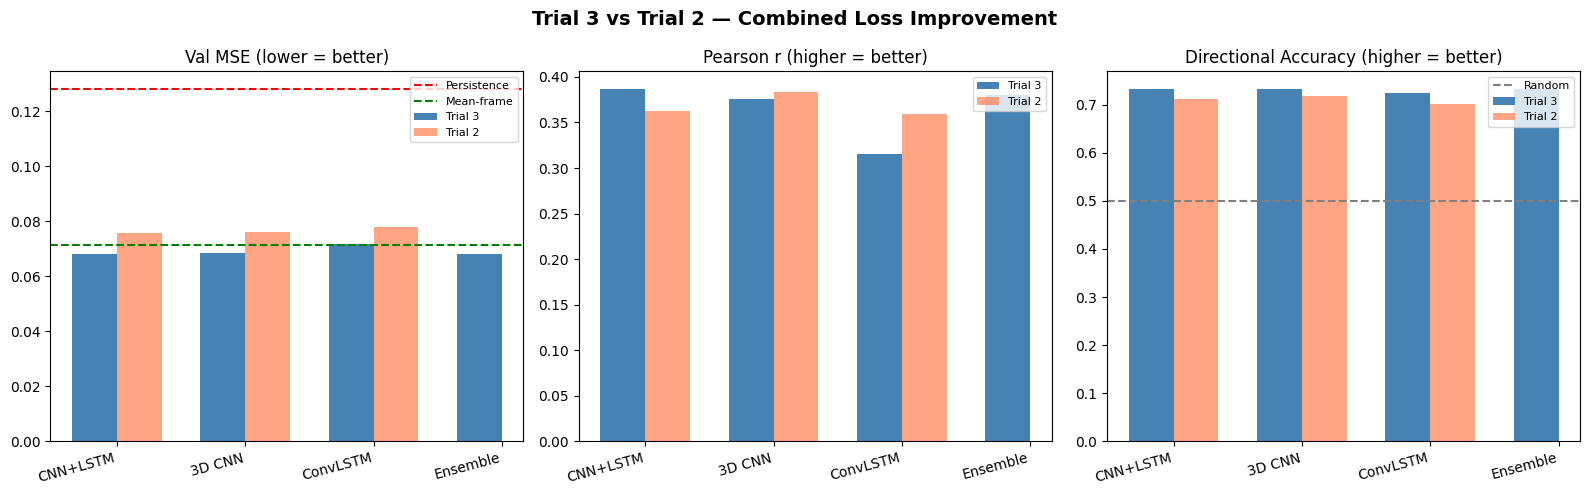

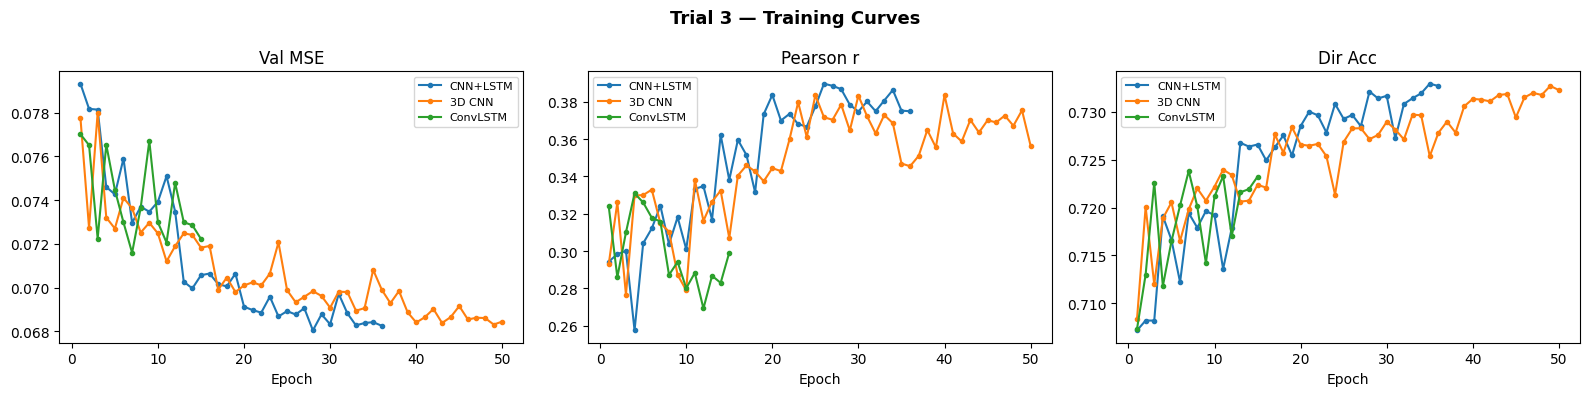


All done. Outputs saved to outputs/plots/ and outputs/predictions/


In [11]:
# Cell 11 – Full Evaluation & Comparison

val_futures = corr_video[val_snaps + HORIZON].astype(np.float32)

# ── Collect metrics for all models + baselines ───────────────────────────
results = {}

preds_dict = {
    'CNN+LSTM'   : np.load(os.path.join(PREDS_DIR, 'trial3_cnn_lstm_val_preds.npy')),
    '3D CNN'     : np.load(os.path.join(PREDS_DIR, 'trial3_3dcnn_val_preds.npy')),
    'ConvLSTM'   : np.load(os.path.join(PREDS_DIR, 'trial3_convlstm_val_preds.npy')),
    'Ensemble'   : np.load(os.path.join(PREDS_DIR, 'trial3_ensemble_val_preds.npy')),
}

for name, preds in preds_dict.items():
    results[name] = compute_metrics(preds, val_futures, val_currents)

# Baselines
results['Persistence'] = dict(mse=persistence_mse, pearson_r=float('nan'),
                               dir_acc=0.5, vs_persist=0.0,
                               vs_mean=(mean_frame_mse - persistence_mse) / mean_frame_mse * 100)
results['Mean-frame']  = dict(mse=mean_frame_mse,  pearson_r=float('nan'),
                               dir_acc=float('nan'), vs_persist=(persistence_mse - mean_frame_mse) / persistence_mse * 100,
                               vs_mean=0.0)

# Trial 2 best results (for reference)
trial2_ref = {
    'T2 CNN+LSTM' : dict(mse=0.075715, pearson_r=0.3623, dir_acc=0.712),
    'T2 3D CNN'   : dict(mse=0.076251, pearson_r=0.3831, dir_acc=0.718),
    'T2 ConvLSTM' : dict(mse=0.078103, pearson_r=0.3592, dir_acc=0.701),
}

# ── Print summary table ────────────────────────────────────────────────────────────
print(f'{"Model":<18} {"Val MSE":>10} {"Pearson r":>10} {"Dir Acc":>9} {"vs Pers":>9} {"vs Mean":>9}')
print('-' * 67)
for name, m in results.items():
    r   = f"{m['pearson_r']:.4f}" if not np.isnan(m['pearson_r']) else '   n/a'
    da  = f"{m['dir_acc']:.3f}"   if m['dir_acc'] is not None and not np.isnan(m['dir_acc']) else '   n/a'
    print(f"{name:<18} {m['mse']:>10.6f} {r:>10} {da:>9} "
          f"{m['vs_persist']:>+8.1f}% {m['vs_mean']:>+8.1f}%")

print('\n--- Trial 2 Reference ---')
print(f'{"Model":<18} {"Val MSE":>10} {"Pearson r":>10} {"Dir Acc":>9}')
print('-' * 47)
for name, m in trial2_ref.items():
    print(f"{name:<18} {m['mse']:>10.6f} {m['pearson_r']:>10.4f} {m['dir_acc']:>9.3f}")

# ── Plots ───────────────────────────────────────────────────────────────────────────────
t3_names   = list(preds_dict.keys())
t3_mse     = [results[n]['mse']       for n in t3_names]
t3_pearson = [results[n]['pearson_r'] for n in t3_names]
t3_dir     = [results[n]['dir_acc']   for n in t3_names]

t2_names   = list(trial2_ref.keys())
t2_mse     = [trial2_ref[n]['mse']       for n in t2_names]
t2_pearson = [trial2_ref[n]['pearson_r'] for n in t2_names]
t2_dir     = [trial2_ref[n]['dir_acc']   for n in t2_names]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle('Trial 3 vs Trial 2 — Combined Loss Improvement', fontsize=14, fontweight='bold')

x3 = np.arange(len(t3_names))
x2 = np.arange(len(t2_names))
w  = 0.35

# Val MSE (lower is better)
ax = axes[0]
ax.bar(x3 - w/2, t3_mse,  w, label='Trial 3', color='steelblue')
ax.bar(x2 + w/2, t2_mse,  w, label='Trial 2', color='coral', alpha=0.7)
ax.axhline(persistence_mse, color='red',   linestyle='--', label='Persistence')
ax.axhline(mean_frame_mse,  color='green', linestyle='--', label='Mean-frame')
ax.set_xticks(x3); ax.set_xticklabels(t3_names, rotation=15, ha='right')
ax.set_title('Val MSE (lower = better)'); ax.legend(fontsize=8)

# Pearson r (higher is better)
ax = axes[1]
ax.bar(x3 - w/2, t3_pearson, w, label='Trial 3', color='steelblue')
ax.bar(x2 + w/2, t2_pearson, w, label='Trial 2', color='coral', alpha=0.7)
ax.set_xticks(x3); ax.set_xticklabels(t3_names, rotation=15, ha='right')
ax.set_title('Pearson r (higher = better)'); ax.legend(fontsize=8)

# Directional accuracy (higher is better)
ax = axes[2]
ax.bar(x3 - w/2, t3_dir, w, label='Trial 3', color='steelblue')
ax.bar(x2 + w/2, t2_dir, w, label='Trial 2', color='coral', alpha=0.7)
ax.axhline(0.5, color='grey', linestyle='--', label='Random')
ax.set_xticks(x3); ax.set_xticklabels(t3_names, rotation=15, ha='right')
ax.set_title('Directional Accuracy (higher = better)'); ax.legend(fontsize=8)

plt.tight_layout()
plt.savefig(os.path.join(PLOTS_DIR, 'trial3_comparison.png'), dpi=150, bbox_inches='tight')
plt.show()

# ── Training curves ───────────────────────────────────────────────────────────────────
hist_dict = {
    'CNN+LSTM' : hist_cnn_lstm,
    '3D CNN'   : hist_3dcnn,
    'ConvLSTM' : hist_convlstm,
}
fig2, axes2 = plt.subplots(1, 3, figsize=(16, 4))
fig2.suptitle('Trial 3 — Training Curves', fontsize=13, fontweight='bold')
metrics_plot = [('va_mse', 'Val MSE'), ('pearson_r', 'Pearson r'), ('dir_acc', 'Dir Acc')]

for ax, (key, label) in zip(axes2, metrics_plot):
    for name, hist in hist_dict.items():
        vals = [h[key] for h in hist if h[key] is not None]
        ax.plot(range(1, len(vals) + 1), vals, label=name, marker='o', markersize=3)
    ax.set_xlabel('Epoch'); ax.set_title(label); ax.legend(fontsize=8)

plt.tight_layout()
plt.savefig(os.path.join(PLOTS_DIR, 'trial3_training_curves.png'), dpi=150, bbox_inches='tight')
plt.show()

print('\nAll done. Outputs saved to outputs/plots/ and outputs/predictions/')